# Checks the processed data for DE_LU before running the full analysis pipeline

In [1]:
import sys; sys.path.insert(0, "..")
import pandas as pd 
import matplotlib.pyplot as plt 
from data_pipeline import schema
from zone_settings import ROOT, get_zone

## Settings

In [2]:
ZONE = "DE_LU"
zone = get_zone(ZONE)
TZ = zone["timezone"]
DATA_PATH = ROOT / "data" / "processed" / f"{ZONE}.csv"
UK_PATH = ROOT / "data" / "market_impact_renewables.csv"
WINDOW_SIZE, STEP_SIZE = 10_000, 1_000 # as used in the DML scripts

## Load zone data

In [3]:
df = pd.read_csv(DATA_PATH, index_col=0, parse_dates=True)
schema.check_columns(df, zone["extra_controls"])
local = df.index.tz_convert(TZ)
print(df.shape)
print("From", local.min(), "to", local.max())

(61317, 15)
From 2019-01-01 00:00:00+01:00 to 2025-12-31 23:00:00+01:00


## Dropped hours

In [4]:
full = pd.date_range(zone["start"], zone["end"], freq="h", inclusive="left").tz_convert("UTC")
dropped = full.difference(df.index).tz_convert(TZ)
print(f"{len(dropped)} hours dropped")
print(pd.Series(1, index=dropped.date).groupby(level=0).size().rename("hours dropped").to_string())

51 hours dropped
2022-02-22    24
2022-03-24    24
2023-10-29     1
2024-10-27     1
2025-10-26     1


## Summary statistics

In [5]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
price,61317.0,94.7,93.8,-500.0,37.7,74.0,114.9,936.3
load_forecast,61317.0,54676.4,9230.8,30893.1,47117.5,54512.2,62309.0,78154.4
wind_forecast,61317.0,14712.3,10759.3,244.6,6075.6,11884.7,21153.8,50447.0
solar_forecast,61317.0,6264.8,9695.0,0.0,0.0,240.1,9957.1,50917.7
wind_capacity,61317.0,65866.5,4908.8,59339.0,61907.0,64557.0,69533.0,76772.0
solar_capacity,61317.0,65670.0,16396.2,45435.0,51817.0,60684.0,79500.0,102606.0
gas_price,61317.0,45.1,44.7,3.5,16.1,32.7,47.2,339.2
co2_price,61317.0,57.7,24.0,14.6,28.0,65.9,78.4,97.5
wind_penetration,61317.0,27.4,20.1,0.4,11.2,22.3,39.1,127.3
solar_penetration,61317.0,10.8,17.0,0.0,0.0,0.4,16.7,103.4


## Value checks

In [6]:
show = {
    "negative price": (df[schema.PRICE]<0).sum(),
    "price at -500 floor": (df[schema.PRICE] <= -500).sum(),
    "price above 500": (df[schema.PRICE] > 500).sum(),
    "wind penetration > 100%": (df[schema.WIND_PENETRATION] > 100).sum(),
    "solar penetration > 100%": (df[schema.SOLAR_PENETRATION] > 100).sum()
}
must_be_zero = {
    "solar > 0 between 00:00 and 03:59": ((df[schema.SOLAR_FORECAST] > 0) & (df[schema.HOUR] <= 3)).sum(),
    "wind forecast > wind capacity": (df[schema.WIND_FORECAST] > df[schema.WIND_CAPACITY]).sum(),
    "solar forecast > solar capacity": (df[schema.SOLAR_FORECAST] > df[schema.SOLAR_CAPACITY]).sum(),
    "negative load or forecasts": (df[[schema.LOAD_FORECAST, schema.WIND_FORECAST, schema.SOLAR_FORECAST]] < 0).any(axis=1).sum()
}
print("To show (real, not errors):"); print(pd.Series(show).to_string())
print("\nMust be zero:"); print(pd.Series(must_be_zero).to_string())
print("\nHighest forecast / capacity: wind %.3f, solar %.3f" % (
    (df[schema.WIND_FORECAST] / df[schema.WIND_CAPACITY]).max(),
    (df[schema.SOLAR_FORECAST] / df[schema.SOLAR_CAPACITY]).max()))
print("\nHours with price above 500, by year:")
print((df[schema.PRICE] > 500).groupby(df[schema.YEAR]).sum().to_string())

To show (real, not errors):
negative price              2051
price at -500 floor            1
price above 500              530
wind penetration > 100%      113
solar penetration > 100%       2

Must be zero:
solar > 0 between 00:00 and 03:59    0
wind forecast > wind capacity        0
solar forecast > solar capacity      0
negative load or forecasts           0

Highest forecast / capacity: wind 0.775, solar 0.682

Hours with price above 500, by year:
year
2019      0
2020      0
2021     14
2022    499
2023      1
2024     15
2025      1


## Time-zone check (solar and price by hour)

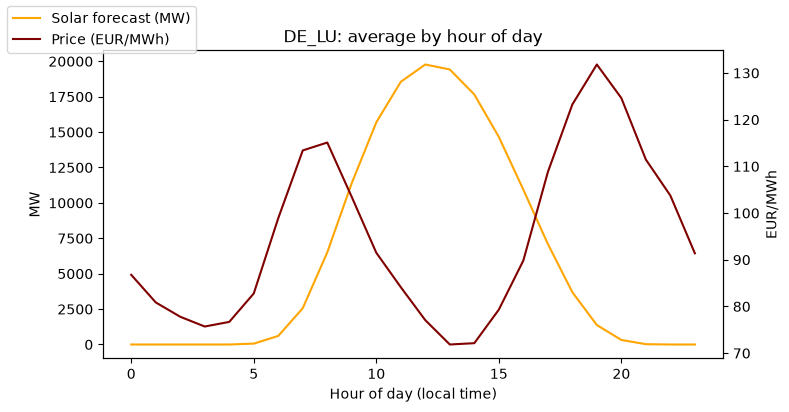

Solar peaks at hour 12


In [7]:
by_hour = df.groupby(schema.HOUR)
fig, ax1 = plt.subplots(figsize=(8,4))
ax1.plot(by_hour[schema.SOLAR_FORECAST].mean(), color="orange", label="Solar forecast (MW)")
ax1.set_xlabel("Hour of day (local time)")
ax1.set_ylabel("MW")
ax2 = ax1.twinx()
ax2.plot(by_hour[schema.PRICE].mean(), color="maroon", label="Price (EUR/MWh)")
ax2.set_ylabel("EUR/MWh")
fig.legend(loc="upper left")
ax1.set_title(f"{ZONE}: average by hour of day")
plt.show()
print("Solar peaks at hour", by_hour[schema.SOLAR_FORECAST].mean().idxmax())